In [1]:
import os
import numpy as np
import pandas as pd
from tqdm import tqdm
from functools import partial
from sklearn.model_selection import train_test_split

from rdkit.Chem import MolFromSmiles, MolToSmiles, MolToInchiKey
from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator
import rdkit.rdBase as rkrb
import rdkit.RDLogger as rkl

import torch
from torch import nn
import torch.nn.functional as F
from torch.nn import TransformerEncoderLayer, TransformerEncoder
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

from tokenizers import Tokenizer, models, trainers
from tokenizers.processors import TemplateProcessing

import lightning as L
from lightning.pytorch import loggers
import gc

tqdm.pandas()

In [2]:
# Competition paths. The input directory is mounted read-only; everything we write goes to
# /kaggle/working, which is what Kaggle collects as the notebook's output.
COMP_DIR = '../data'
TRAIN_PATH = os.path.join(COMP_DIR, 'train.parquet')
TEST_PATH = os.path.join(COMP_DIR, 'test.parquet')
SAMPLE_SUBMISSION_PATH = os.path.join(COMP_DIR, 'sample_submission.csv')

WORKING_DIR = 'working'
SUBMISSION_PATH = os.path.join(WORKING_DIR, 'submission.csv')

print(os.listdir(COMP_DIR))

['train.parquet', 'sample_submission.csv', 'test.parquet']


In [3]:
# disable rdkit warning logs
# necessary because we'll be attempting to decode lots of invalid smiles during training
logger = rkl.logger()
logger.setLevel(rkl.ERROR)
rkrb.DisableLog("rdApp.error") 

# Data

## load data

In [4]:
NEEDED = ['ingest_lib', 'inchikey14', 'normalized_smiles', 'precursor_mz',
          'ms2_mzs', 'ms2_normalized_intensities', 'precursor_mz', 'adduct', 
          'ionization_mode', 'collision_energy_ev']
casmi_all_df = pd.read_parquet(TRAIN_PATH, columns=NEEDED,
                             filters=[('ingest_lib', '!=', 'enveda-180')])

# split into train, val
all_structs = casmi_all_df.inchikey14.unique().to_numpy()
train_structs, val_structs = train_test_split(all_structs, test_size=500, random_state=0)
casmi_train_df = casmi_all_df[casmi_all_df.inchikey14.isin(train_structs)]
casmi_val_df = casmi_all_df[casmi_all_df.inchikey14.isin(val_structs)]

# Cap the training set so a Kaggle session finishes. Measured at ~840 ms/step on a T4 at batch 128
# and MAX_LEN 128, so 200k spectra is ~1,560 steps, roughly 22 minutes. All 1.39M spectra would be
# ~2.5 hours of training before validation. Set to None to use everything.
MAX_TRAIN_SPECTRA = 500
if MAX_TRAIN_SPECTRA is not None and len(casmi_train_df) > MAX_TRAIN_SPECTRA:
    casmi_train_df = casmi_train_df.sample(n=MAX_TRAIN_SPECTRA, random_state=0)

# One spectrum per val structure. Validation generates autoregressively with no KV cache, so
# validating all 8,447 val spectra costs more than the training epoch itself.
casmi_val_df = casmi_val_df.drop_duplicates(subset=['inchikey14'], keep='first')

print('split: spectra count, structure count')
print('train:', len(casmi_train_df), casmi_train_df.inchikey14.nunique())
print('val:', len(casmi_val_df), casmi_val_df.inchikey14.nunique())

split: spectra count, structure count
train: 500 493
val: 500 500


## process data

In [5]:
# data processing params
# 128, not 512. The collator pads each batch to its longest spectrum, and although the median
# spectrum has only 20 peaks, 95% of batches contain at least one long one -- so at MAX_LEN=512
# nearly every batch ran 512-length attention over mostly padding. Measured on a T4: batch 128 at
# seq 512 needs 16.0 GB and OOMs a 14.56 GB card; at seq 128 it needs 6.4 GB. Peaks are sorted by
# intensity before truncation, so this keeps every peak for 89.5% of spectra and the 127 most
# intense for the rest. Raise to 256 (9.8 GB, 94.8% complete) if you want more of the tail.
MAX_LEN = 128
BPE_PAD_ID = 0
BPE_BOS_ID = 1
BPE_EOS_ID = 2
VOCAB_SIZE = 512

In [6]:
# process data
## spectrum transform
def process_spectra(df):
    def _process_spectrum(row):
        # sort mzs, intensities
        sort_mask = np.argsort(row.ms2_normalized_intensities)[::-1]
        sorted_mzs = row.ms2_mzs[sort_mask]
        sorted_intensities = row.ms2_normalized_intensities[sort_mask]
    
        # truncate to max len
        truncated_mzs = sorted_mzs[:MAX_LEN - 1] # note: we use MAX_LEN - 1 to account for the precursor, which will be prepended
        truncated_intensities = sorted_intensities[:MAX_LEN - 1]
        
        # normalize intensities
        normalized_intensities = truncated_intensities / truncated_intensities.max()
    
        return truncated_mzs, normalized_intensities

    mzs, ints = zip(*df.progress_apply(_process_spectrum, axis=1))
    df['processed_mzs'] = mzs
    df['processed_intensities'] = ints
    return df

## transform spectra
print('processing spectra...')
casmi_train_df = process_spectra(casmi_train_df)
casmi_val_df = process_spectra(casmi_val_df)

## smiles bpe tokenizer
def train_bpe_tokenizer(structures):
    os.environ["TOKENIZERS_PARALLELISM"] = "true"     # turn on tokenizers parallelism to speed up bpe training
    
    full_alphabet = list(set(list("".join(structures))))
    tokenizer = Tokenizer(models.BPE())
    special_tokens = [
        ("<pad>", BPE_PAD_ID),
        ("<s>", BPE_BOS_ID),
        ("</s>", BPE_EOS_ID),
    ]
    tokenizer.post_processor = TemplateProcessing(
        single="<s> $A </s>", special_tokens=special_tokens
    )
    special_tokens = ["<pad>", "<s>", "</s>"]
    
    trainer = trainers.BpeTrainer(
        vocab_size=VOCAB_SIZE,
        initial_alphabet=full_alphabet,
        special_tokens=special_tokens,
        show_progress=True,
    )
    train_iterator = structures
    tokenizer.train_from_iterator(train_iterator, trainer)
    
    os.environ["TOKENIZERS_PARALLELISM"] = "false"     # turn off tokenizers parallelism
    return tokenizer

def tokenize_df_smiles(df, tokenizer):
    df['bpe_tokenized_smiles'] = df.normalized_smiles.progress_apply(
        lambda x: np.array(tokenizer.encode(x).ids, dtype=int)
    )
    return df

## tokenize smiles
print('training bpe...')
bpe_train_structures = list(casmi_train_df.normalized_smiles.unique())
tokenizer = train_bpe_tokenizer(bpe_train_structures)

print('processing smiles...')
casmi_train_df = tokenize_df_smiles(casmi_train_df, tokenizer=tokenizer)
casmi_val_df = tokenize_df_smiles(casmi_val_df, tokenizer=tokenizer)

# utility for decoding bpe smiles
def decode_tokenized_smiles(bpe_smiles_tokens, tokenizer=tokenizer):
    return tokenizer.decode(bpe_smiles_tokens).replace(' ', '')

processing spectra...


100%|██████████| 500/500 [00:00<00:00, 27710.05it/s]


training bpe...



processing smiles...


100%|██████████| 500/500 [00:00<00:00, 62230.03it/s]


In [34]:
casmi_train_df

,ingest_lib,inchikey14,normalized_smiles,precursor_mz,ms2_mzs,ms2_normalized_intensities,precursor_mz,adduct,ionization_mode,collision_energy_ev,processed_mzs,processed_intensities,bpe_tokenized_smiles
1063830,riken,GMCGZPQYTRHQRU,CC(CCC1(O)OC2CC3C4CC=C5CC(OC6OC(CO)C(O)C(OC7OC...,1065.5400,"[299.109, 647.208, 648.211, 1065.415, 1065.475...","[0.034, 0.218, 0.073, 0.005, 0.029, 0.007, 0.0...",1065.5400,[M+H]+,positive,[10.0],"[1067.488, 1068.495, 647.208, 1069.481, 648.21...","[1.0, 0.445, 0.218, 0.08, 0.073, 0.047, 0.034,...","[1, 54, 172, 96, 152, 142, 444, 249, 327, 95, ..."
851434,pluskal_ms2,SYTMUAVLSMHWLV,Cc1cc2c(NC3CN(c4cc(C(F)(F)F)ccn4)C3)nccn2n1,347.1237,"[106.0411, 128.0318, 132.0568, 146.0223, 146.0...","[0.049669, 0.019844, 0.006798, 0.02545, 0.0947...",347.1237,[M-H]-,negative,[20.8],"[161.0334, 173.0834, 175.049, 147.0677, 347.12...","[1.0, 0.703914, 0.458634, 0.239264, 0.229455, ...","[1, 169, 11, 173, 56, 230, 104, 70, 177, 165, ..."
996209,riken,AOUZZRQCLQLQIF,CC(C)=CCc1c2c(cc3ccc(=O)oc13)CC(C(C)(C)O)O2,332.1856,"[55.018, 59.049, 65.039, 67.054, 83.013, 91.05...","[0.015, 0.025, 0.014, 0.032, 0.068, 0.078, 0.0...",332.1856,[M+NH4]+,positive,[43.2],"[199.039, 171.044, 187.039, 203.034, 195.081, ...","[1.0, 0.78, 0.538, 0.202, 0.195, 0.19, 0.172, ...","[1, 205, 308, 157, 190, 39, 103, 35, 44, 102, ..."
728319,pluskal_ms2,NIDVTARKFBZMOT,CC(=O)Nc1ccn(C2OC(CO)C(O)C2O)c(=O)n1,286.1034,"[43.0184, 112.0505, 112.0583, 112.0647, 112.06...","[0.00198, 0.18357, 0.00319, 0.00205, 0.00159, ...",286.1034,[M+H]+,positive,[8.6],"[154.0612, 112.0505, 154.0906, 154.0315, 154.0...","[1.0, 0.18357, 0.00721, 0.00702, 0.00627, 0.00...","[1, 182, 52, 199, 483, 179, 374, 2]"
278124,massbank,NXFQWRWXEYTOTK,COc1nc(C)nc(N)n1,141.0771,"[30.0338, 42.0338, 43.0291, 43.0542, 44.0131, ...","[0.038038, 0.833834, 1.0, 0.02002, 0.014014, 0...",141.0771,[M+H]+,positive,[40.0],"[43.0291, 42.0338, 58.0287, 57.0447, 68.0243, ...","[1.0, 0.833834, 0.783784, 0.603604, 0.274274, ...","[1, 494, 131, 200, 115, 68, 2]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...
596539,pluskal_ms2,HHVBKVQERRETLY,Cc1cc(=O)c(C(=O)N2CCCC(c3nn[nH]n3)C2)nn1-c1ccc...,432.1401,"[42.0096, 65.9983, 68.9959, 138.0352, 166.0303...","[1.0, 0.14292, 0.0986, 0.08598, 0.22711, 0.258...",432.1401,[M-H]-,negative,[51.9],"[42.0096, 173.5431, 166.0303, 65.9983, 205.085...","[1.0, 0.2581, 0.22711, 0.14292, 0.11342, 0.098...","[1, 169, 66, 406, 11, 474, 227, 34, 90, 34, 10..."
97116,gnps,LICPIHGCVIIIQA,CCCCCCCCCNCCc1c[nH]c2ccc(O)cc12,303.2420,"[50.6787, 52.2136, 56.262, 57.1557, 63.1995, 6...","[0.013468, 0.013206, 0.01322, 0.012385, 0.0168...",303.2420,[M+H]+,positive,None,"[160.0755, 256.8847, 156.1745, 258.1159, 303.2...","[1.0, 0.375433, 0.294206, 0.195392, 0.166041, ...","[1, 97, 91, 308, 379, 217, 11, 2]"
512690,pluskal_ms2,CLGMYHRDSZNICY,Fc1ccc(OCCNc2cc(C(F)(F)F)ncn2)cc1,336.0532,"[111.0252, 111.0345]","[1.0, 0.022758]",336.0532,[M+Cl]-,negative,[40.3],"[111.0252, 111.0345]","[1.0, 0.022758]","[1, 22, 71, 457, 186, 267, 460, 195, 2]"
971591,pluskal_ms2,ZHPGPRJUFPAGNF,N#Cc1ccc(NCc2cccc(Br)c2)cn1,321.9752,"[173.5394, 285.9982]","[0.66598, 1.0]",321.9752,[M+Cl]-,negative,[12.9],"[285.9982, 173.5394]","[1.0, 0.66598]","[1, 25, 3, 197, 25, 21, 58, 70, 237, 6, 144, 2..."


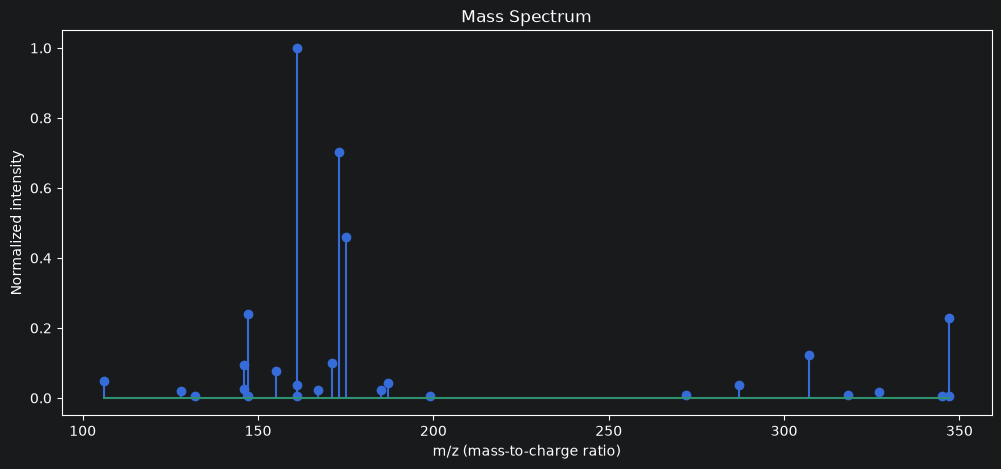

Cc1cc2c(NC3CN(c4cc(C(F)(F)F)ccn4)C3)nccn2n1


In [7]:
import matplotlib.pyplot as plt

# Get the first row
row = casmi_train_df.iloc[1]

# Get the measurements
mzs = row["processed_mzs"]
intensities = row["processed_intensities"]

# Draw the plot
plt.figure(figsize=(12, 5))
plt.stem(mzs, intensities)

plt.xlabel("m/z (mass-to-charge ratio)")
plt.ylabel("Normalized intensity")
plt.title("Mass Spectrum")
plt.show()
print(row['normalized_smiles'])

## datamodule class

In [8]:
# datamodule params
PRECURSOR_INTENSITY = 2.0
MZ_PAD_ID = 0
INTENSITY_PAD_ID = 0
BATCH_SIZE = 32
# A Kaggle T4 session has 4 vCPUs. This was defined but never passed to a DataLoader, which is
# what Lightning's 'does not have many workers' warning was about.
NUM_WORKERS = 3

In [9]:
class PandasDataset(Dataset):
    def __init__(self, df, column_list, shuffle=True):
        # Prediction keeps the original row order so rows stay aligned with their molecule_id.
        self.df = df[column_list].sample(frac=1, random_state=0) if shuffle else df[column_list]

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        return self.df.iloc[idx].to_dict()

In [10]:
# define datamodule class
ADDUCT_MAP = {
    "[M+H]+": 0,
    "[M-H]-": 1,
    "[M+Na]+": 2,
    "[M+K]+": 3,
}

ION_MODE_MAP = {
    "positive": 0,
    "negative": 1,
}

class CASMIDataModule(L.LightningDataModule):
    def __init__(self, batch_size, predict_batch_size=None):
        super().__init__()
        self.batch_size = batch_size
        # Generation expands the batch by n_samples, so prediction needs a far smaller batch than
        # training. See the predict cell for the arithmetic.
        self.predict_batch_size = predict_batch_size or batch_size

    def setup(self, stage):
        columns = ['precursor_mz', 'processed_mzs', 'processed_intensities', 'bpe_tokenized_smiles', 'normalized_smiles']
        if stage == "fit":
            self.train_df = PandasDataset(casmi_train_df, column_list=columns)
            self.val_df = PandasDataset(casmi_val_df, column_list=columns)
        elif stage == "validate":
            self.val_df = PandasDataset(casmi_val_df, column_list=columns)
        elif stage == "predict":
            # test.parquet carries no labels, so only the spectrum columns exist. molecule_id rides
            # along because scoring is per molecule, not per spectrum, and a molecule's spectra have
            # to be grouped back together afterwards.
            self.predict_df = PandasDataset(
                casmi_test_df,
                column_list=['molecule_id', 'precursor_mz', 'processed_mzs', 'processed_intensities'],
                shuffle=False,
            )

    def train_dataloader(self):
        return DataLoader(
            self.train_df,
            batch_size=self.batch_size,
            collate_fn=self.get_collator('fit'),
            num_workers=0,
            pin_memory=True,
        )

    def val_dataloader(self):
        return DataLoader(
            self.val_df,
            batch_size=self.batch_size,
            collate_fn=self.get_collator('validate'),
            num_workers=0,
            pin_memory=True,
        )

    def predict_dataloader(self):
        return DataLoader(
            self.predict_df,
            batch_size=self.predict_batch_size,
            collate_fn=self.get_collator('predict'),
            num_workers=0,
            pin_memory=True,
        )

    def get_collator(self, stage):
        return partial(self._collator, stage=stage)

    def _collator(self, data, stage='fit'):
        mzs = [[row['precursor_mz']] + row['processed_mzs'].tolist() for row in data]  # prepend precursor to m/zs
        ints = [[PRECURSOR_INTENSITY] + row['processed_intensities'].tolist() for row in data]  # prepend 2. to intensities
        if stage == 'fit' or stage == 'validate':
            labels = [row['bpe_tokenized_smiles'] for row in data]

        precursor_mz = torch.tensor(
            [row["precursor_mz"] for row in data],
            dtype=torch.float32
        )

        collision_energy = torch.tensor(
        [
            row.get("collision_energy_ev", 0.0)[0]
            if isinstance(row.get("collision_energy_ev", 0.0), (list, np.ndarray))
            else row.get("collision_energy_ev", 0.0)
            for row in data
        ],
        dtype=torch.float32,
        )

        adduct = torch.tensor(
            [ADDUCT_MAP.get(row.get("adduct"), -1) for row in data]
        )
        ion_mode = torch.tensor(
            [
            ION_MODE_MAP.get(
                row.get("ionization_mode", "unknown"),
                -1
            )
            for row in data
            ]
        )        
        # collate peaks
        max_peak_len = max([len(x) for x in mzs])
        mzs = [list(x) + [MZ_PAD_ID] * (max_peak_len - len(x)) for x in mzs]
        ints = [list(x) + [INTENSITY_PAD_ID] * (max_peak_len - len(x)) for x in ints]
        mz_array = torch.tensor(mzs)
        intensity_array = torch.tensor(ints)
        attention_mask = torch.where(mz_array == MZ_PAD_ID, 0, 1) # attention_mask is being created to ignore padding tokens

        metadata = torch.tensor(
            list(
                zip(
                    precursor_mz,
                    collision_energy,
                    adduct,
                    ion_mode,
                )
            ),
            dtype=torch.float32,
        )
        
        # collate labels
        batch = {}
        if stage == 'fit' or stage == 'validate':
            max_smiles_len = max([len(x) for x in labels])
            labels = [list(x) + [BPE_PAD_ID] * (max_smiles_len - len(x)) for x in labels]
            label_array = torch.tensor(labels)

            batch['mzs'] = mz_array
            batch['intensities'] = intensity_array
            batch['attention_mask'] = attention_mask
            batch['structure_tokens'] = label_array # tokenized labels for training
            batch['metadata'] = metadata
        if stage == 'validate':
            batch['smiles'] = [row['normalized_smiles'] for row in data] # include original smiles for validation metrics
        else:
            batch = batch | {
                'mzs': mz_array,
                'intensities': intensity_array,
                'attention_mask': attention_mask,
                'metadata': metadata
            }
        if stage == 'predict':
            batch['molecule_id'] = [row['molecule_id'] for row in data]
        return batch

# define datamodule
datamodule = CASMIDataModule(batch_size=BATCH_SIZE)
datamodule.setup('fit')

In [11]:
# confirm the dataloader works
val_dl = datamodule.val_dataloader()
for batch in val_dl:
    break
print(batch['mzs'].shape)
print(batch['intensities'].shape)
print(batch['attention_mask'].shape)
print(batch['structure_tokens'].shape)
print(batch['metadata'].shape)
print(len(batch['smiles']))

torch.Size([32, 128])
torch.Size([32, 128])
torch.Size([32, 128])
torch.Size([32, 30])
torch.Size([32, 4])
32


# Model

In [12]:
# define tanimoto similarity for metrics

## we'll use Morgan radius 2 fps to define "tanimoto similarity" in this notebook
### note: radius 2, counts=True, sparse (no hashing)
fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2)

def tanimoto_smiles(smiles1, smiles2):
    mol1, mol2 = MolFromSmiles(smiles1), MolFromSmiles(smiles2)
    if mol1 is None or mol2 is None:
        return None
    fp1, fp2 = fp_gen.GetSparseFingerprint(mol1), fp_gen.GetSparseFingerprint(mol2)
    return DataStructs.TanimotoSimilarity(fp1, fp2)

In [13]:
# define module classes

class MetadataEmbedder(nn.Module):
    def __init__(self, d_model):
        super().__init__()
        self.encoder = nn.Sequential(
        nn.Linear(4, d_model),
        nn.ReLU(),
        nn.Linear(d_model, d_model)
        )

    def forward(self, metadata):
        return self.encoder(metadata)

### peak embedder
class PeakEmbedder(nn.Module):
    """embed (m/z, intensity) peak pairs with sinusoidal embeddings from Voronov et al"""
    def __init__(self, d_model, dropout, sin_dim=None, mz_log_lims=(-2., 3.), mz_log_power=1.0):
        super().__init__()
        sin_dim = sin_dim if sin_dim is not None else d_model
        self.dropout = dropout

        wavelength = torch.pow(
            10,
            (mz_log_lims[1] - mz_log_lims[0]) * torch.pow(
                torch.linspace(0, 1, int(sin_dim / 2)), 
                mz_log_power,
            ) + mz_log_lims[0],
        )
        frequency = 2 * np.pi / wavelength
        self._frequency = nn.Parameter(frequency, requires_grad=False)
        self._ff_block_1 = nn.Sequential(*[
            nn.Linear(sin_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, d_model),
            nn.Dropout(dropout),
        ])
        self._ff_block_2 = nn.Sequential(*[
            nn.Linear(d_model+1, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, d_model),
            nn.Dropout(dropout),
        ])

    def forward(self, mz_tensor, intensity_tensor):
        # "mz embedding" embeds just the m/z value
        omega_mz = self._frequency.view(
            *(1 for _ in range(mz_tensor.ndim)), -1
        ) * mz_tensor.unsqueeze(-1)
        sin = torch.sin(omega_mz)
        cos = torch.cos(omega_mz)
        mz_vecs = torch.cat([sin, cos], dim=-1)
        mz_embeds = self._ff_block_1(mz_vecs)

        # "peak embedding" embeds both the m/z and intensity
        peak_embeds = torch.cat([mz_embeds, intensity_tensor.unsqueeze(2)], dim=2)
        peak_embeds = self._ff_block_2(peak_embeds)
        return peak_embeds

        
### spectrum encoder
class SpectrumEncoder(nn.Module):
    def __init__(self, embed_dim, n_heads, n_layers, dim_feedforward=None, dropout=0.1, activation='relu'):
        super().__init__()
        dim_feedforward = dim_feedforward if dim_feedforward is not None else 4 * embed_dim
        self.encoder = TransformerEncoder(
            TransformerEncoderLayer(
                embed_dim,
                n_heads,
                dim_feedforward=dim_feedforward,
                batch_first=True,
                dropout=dropout,
                activation=activation,
            ),
            n_layers,
        )
        self.init_weights()

    def forward(self, sequence_input, attention_mask):
        pad_mask = (attention_mask == 0)
        return self.encoder(sequence_input, src_key_padding_mask=pad_mask)

    def init_weights(self):
        for layer in self.encoder.layers:
            for name, mod in layer.named_modules():
                if isinstance(mod, nn.Linear):
                    nn.init.xavier_uniform_(mod.weight)
                    if mod.bias is not None:
                        nn.init.constant_(mod.bias, 0.0)
                elif isinstance(mod, nn.LayerNorm):
                    nn.init.constant_(mod.weight, 1.0)
                    if mod.bias is not None:
                        nn.init.constant_(mod.bias, 0.0)

from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig, get_peft_model
### smiles decoder
class LlamaSmilesDecoder(nn.Module):
    def __init__(
            self,
            encoder_dim,
            model_name="meta-llama/Llama-3.2-1B",
            lora_r=16,
            lora_alpha=32,
            lora_dropout=0.05,
            target_modules=("q_proj", "k_proj", "v_proj", "o_proj",
                            "gate_proj", "up_proj", "down_proj"),
            max_smiles_tokens=128,
            torch_dtype=torch.bfloat16,
            validate_n_samples=10,
            predict_n_samples=25,
    ):
        super().__init__()
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        self.eos_token_id = self.tokenizer.eos_token_id
        self.bos_token_id = self.tokenizer.bos_token_id if self.tokenizer.bos_token_id is not None else self.eos_token_id
        self.pad_token_id = self.tokenizer.pad_token_id if self.tokenizer.pad_token_id is not None else self.eos_token_id
        self.max_smiles_tokens = max_smiles_tokens
        self.n_samples_per_stage = {'validate': validate_n_samples, 'predict': predict_n_samples}

        llm = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype=torch_dtype)
        lora_cfg = LoraConfig(
            r=lora_r,
            lora_alpha=lora_alpha,
            lora_dropout=lora_dropout,
            target_modules=list(target_modules),
            bias="none",
            task_type="CAUSAL_LM",
        )
        self.llm = get_peft_model(llm, lora_cfg)  # freezes base weights, adds adapters
        hidden = llm.config.hidden_size

        self.projector = nn.Sequential(
            nn.Linear(encoder_dim, hidden),
            nn.GELU(),
            nn.Linear(hidden, hidden),
        )
        self.prefix_norm = nn.LayerNorm(hidden)

    # ---------- helpers ----------
    def _embed(self, ids):
        return self.llm.get_input_embeddings()(ids)

    def _project(self, encoder_outputs):
        prefix = self.prefix_norm(self.projector(encoder_outputs))
        return prefix.to(self.llm.get_input_embeddings().weight.dtype)

    @staticmethod
    def _position_ids(attn):
        # padded peaks sit in the middle of the sequence, so derive positions from the mask
        return (attn.cumsum(-1) - 1).clamp(min=0)

    def _token_mask(self, idx):
        # real tokens = everything up to and including the first EOS (position 0 is BOS)
        is_eos = (idx == self.eos_token_id).long()
        is_eos[:, 0] = 0
        return (is_eos.cumsum(-1) - is_eos) == 0

    def tokenize(self, smiles, device=None):
        """list[str] -> (B, T) LongTensor: [BOS] smiles [EOS] [PAD...]"""
        ids = self.tokenizer(list(smiles), add_special_tokens=False)["input_ids"]
        ids = [[self.bos_token_id] + x[: self.max_smiles_tokens] + [self.eos_token_id] for x in ids]
        T = max(len(x) for x in ids)
        out = torch.full((len(ids), T), self.pad_token_id, dtype=torch.long)
        for i, x in enumerate(ids):
            out[i, : len(x)] = torch.tensor(x)
        return out.to(device) if device is not None else out

    def decode(self, token_ids):
        """list[int] (starting with BOS) -> SMILES string"""
        ids = list(token_ids)[1:]
        if self.eos_token_id in ids:
            ids = ids[: ids.index(self.eos_token_id)]
        return self.tokenizer.decode(ids, skip_special_tokens=True).replace(" ", "").strip()

    # ---------- same signature as before ----------
    def forward(self, idx, encoder_outputs, encoder_attention_mask, structure_tokens=None):
        S = encoder_outputs.shape[1]
        tok_mask = self._token_mask(idx)
        inputs_embeds = torch.cat([self._project(encoder_outputs), self._embed(idx)], dim=1)
        attn = torch.cat([encoder_attention_mask.long(), tok_mask.long()], dim=1)

        x = self.llm(
            inputs_embeds=inputs_embeds,
            attention_mask=attn,
            position_ids=self._position_ids(attn),
        )
        logits = x.logits[:, S:].float()          # keep only the SMILES positions

        output_dict = {'logits': logits}
        if structure_tokens is not None:
            # logits at t predict token t+1 (the LLM is a standard causal LM)
            labels = structure_tokens[:, 1:].masked_fill(~tok_mask[:, 1:], -100)
            loss = F.cross_entropy(
                logits[:, :-1].reshape(-1, logits.size(-1)),
                labels.reshape(-1),
                ignore_index=-100,
                reduction='mean',
            )
            output_dict['loss'] = loss
        return output_dict

    @torch.inference_mode()
    def generate(
        self,
        encoder_states,
        encoder_mask,
        n_samples=1,
        max_new_tokens=50,
        temperature=1.0,
    ):
        """sampling based generation; returns (B, n_samples, L) token ids (starting with BOS) and (B, n_samples) log-probs"""
        B = encoder_states.shape[0]
        dev = encoder_states.device
        prefix = self._project(encoder_states)
        bos = torch.full((B, 1), self.bos_token_id, dtype=torch.long, device=dev)
        inputs_embeds = torch.cat([prefix, self._embed(bos)], dim=1)
        attn = torch.cat([encoder_mask.long(), torch.ones(B, 1, dtype=torch.long, device=dev)], dim=1)

        inputs_embeds = inputs_embeds.repeat_interleave(n_samples, dim=0)
        attn = attn.repeat_interleave(n_samples, dim=0)

        out = self.llm.generate(
            inputs_embeds=inputs_embeds,
            attention_mask=attn,
            do_sample=True,
            temperature=temperature,
            top_k=0,
            top_p=1.0,
            max_new_tokens=max_new_tokens,
            eos_token_id=self.eos_token_id,
            pad_token_id=self.pad_token_id,
            return_dict_in_generate=True,
            output_scores=True,
        )
        seq = out.sequences                                           # (B*n, T), new tokens only
        logp = torch.stack(out.scores, dim=1).log_softmax(-1)         # (B*n, T, V)
        tok_logp = logp.gather(-1, seq.unsqueeze(-1)).squeeze(-1)

        is_eos = (seq == self.eos_token_id).long()
        after_eos = (is_eos.cumsum(-1) - is_eos) > 0                  # tokens after first EOS
        tok_logp = tok_logp.masked_fill(after_eos, 0.0)

        idx = torch.cat([bos.repeat_interleave(n_samples, dim=0), seq], dim=1)
        _, Lq = idx.shape
        return idx.reshape(B, n_samples, Lq), tok_logp.sum(dim=-1).reshape(B, n_samples)

In [14]:
class DeNovoLightningModel(L.LightningModule):
    def __init__(self, kwargs):
        super().__init__()
        self.peak_embedder = PeakEmbedder(**kwargs['peak_embedder'])
        self.spectrum_encoder = SpectrumEncoder(**kwargs['spectrum_encoder'])
        self.smiles_decoder = LlamaSmilesDecoder(**kwargs['smiles_decoder'])
        self.optimizer_config = kwargs['optimizer']

    def forward(self, batch, stage, return_encoder_states=False):
        encoded_spectra = self.spectrum_encoder(
            self.peak_embedder(batch['mzs'], batch['intensities']),
            batch['attention_mask']
        )
        outputs = {}
        if stage in ('fit', 'validate'):
            outputs = self.smiles_decoder(
                batch['structure_tokens'],
                encoded_spectra,
                batch['attention_mask'],
                structure_tokens=batch['structure_tokens']
            )
        if stage in ('validate', 'predict'):
            tokens, scores = self.smiles_decoder.generate(
                encoded_spectra,
                batch['attention_mask'],
                n_samples=self.smiles_decoder.n_samples_per_stage[stage],
                temperature=1., # experiment with this
            )
            outputs['generated_tokens'] = tokens
            outputs['generated_scores'] = scores
        if return_encoder_states:
            outputs['encoder_states'] = encoded_spectra
        return outputs

    def training_step(self, batch):
        outputs = self(batch, "fit")
        loss = outputs['loss']
        self.log(
            "train_loss",
            loss,
            sync_dist=True,
            prog_bar=True,
            on_step=True,
            on_epoch=True,
            logger=True,
            batch_size=batch['mzs'].shape[0],
        )
        return loss

    def validation_step(self, batch):
        forward_outputs = self(batch, "validate", return_encoder_states=True)
        loss = forward_outputs['loss']
        generated_tokens, generated_scores = self.smiles_decoder.generate(
            forward_outputs['encoder_states'],
            batch['attention_mask'],
            n_samples=10,
            temperature=1.0,
        )
        generation_metrics = self.compute_val_metrics(
            generated_tokens,
            generated_scores,
            batch['smiles']
        )

        metrics_dict = {
            "val_loss": loss,
            **{f"val_{k}": v for k, v in generation_metrics.items()},
        }
        self.log_dict(
            metrics_dict,
            add_dataloader_idx=False,
            on_epoch=True,
            sync_dist=True,
            batch_size=(batch['mzs'].shape[0]),
        )

    def predict_step(self, batch):
        # forward() already generates for stage='predict'; generating a second time here just did
        # the same expensive sampling twice.
        outputs = self(batch, "predict")
        return batch['molecule_id'], outputs['generated_tokens'], outputs['generated_scores']

    def compute_val_metrics(self, generated_tokens, generated_scores, labels):
        decoded_smiles = [
            [decode_tokenized_smiles(tokens.tolist()) for tokens in token_seqs]
            for token_seqs in generated_tokens
        ]
        score_masks = [scores.argsort(descending=True) for scores in generated_scores]
        sorted_valid_smiles = [
            [smiles_seq[idx] for idx in mask if smiles_seq[idx] != '' and MolFromSmiles(smiles_seq[idx]) is not None]
            for smiles_seq, mask in zip(decoded_smiles, score_masks)
        ]
        top_valid_smiles = [
            smiles_seq[0]
            if len(smiles_seq) > 0 else None
            for smiles_seq in sorted_valid_smiles
        ]

        def _sm_to_ikey(smiles):
            return MolToInchiKey(MolFromSmiles(smiles)).split('-')[0]
        ikey_match = [
            _sm_to_ikey(smiles) == _sm_to_ikey(label)
            if smiles is not None else False
            for smiles, label in zip(top_valid_smiles, labels)
        ]
        tanimotos = [
            tanimoto_smiles(smiles, label)
            if smiles is not None else 0.0
            for smiles, label in zip(top_valid_smiles, labels)
        ]

        frac_ikey_match = np.mean(ikey_match)
        frac_valid_smiles = np.mean([x is not None for x in top_valid_smiles])
        mean_tanimoto = np.mean(tanimotos)

        return {
            'valid_smiles': frac_valid_smiles,
            'tanimoto': mean_tanimoto,
            'exact match': frac_ikey_match,
        }

    def configure_optimizers(self):
        return AdamW(
            self.parameters(),
            lr=self.optimizer_config['lr'],
        )

In [15]:
# model hyperparams
EMBED_DIM = 768
DIM_FEEDFORWARD = 3072
DROPOUT = 0.1

ENCODER_N_HEADS = 12
ENCODER_N_LAYERS = 6
ENCODER_ACTIVATION = 'gelu'

# LLM decoder (replaces DECODER_N_HEADS / N_LAYERS / ACTIVATION)
LLM_NAME = "meta-llama/Llama-3.2-1B"   # or 'Qwen/Qwen2.5-0.5B' if you don't want a gated model
LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05
MAX_SMILES_TOKENS = 128

N_SAMPLES_VAL = 10
N_SAMPLES_PRED = 25

LEARNING_RATE = 5e-5      # spectrum encoder, embedders, projector
LORA_LEARNING_RATE = 2e-4 # LoRA adapters

In [16]:
model_params = {
    'peak_embedder': {
        'd_model': EMBED_DIM,
        'dropout': DROPOUT,
    },
    'metadata_embedder': {
        'd_model': EMBED_DIM,
    },
    'spectrum_encoder': {
        'embed_dim': EMBED_DIM,
        'n_heads': ENCODER_N_HEADS,
        'n_layers': ENCODER_N_LAYERS,
        'dim_feedforward': DIM_FEEDFORWARD,
        'dropout': DROPOUT,
        'activation': ENCODER_ACTIVATION,
    },
    'smiles_decoder': {
        'encoder_dim': EMBED_DIM,
        'model_name': LLM_NAME,
        'lora_r': LORA_R,
        'lora_alpha': LORA_ALPHA,
        'lora_dropout': LORA_DROPOUT,
        'max_smiles_tokens': MAX_SMILES_TOKENS,
        'validate_n_samples': N_SAMPLES_VAL,
        'predict_n_samples': N_SAMPLES_PRED,
    },
    'optimizer': {
        'lr': LEARNING_RATE,
        'lora_lr': LORA_LEARNING_RATE,
    },
}
model = DeNovoLightningModel(model_params)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

In [17]:
model

DeNovoLightningModel(
  (peak_embedder): PeakEmbedder(
    (_ff_block_1): Sequential(
      (0): Linear(in_features=768, out_features=768, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=768, out_features=768, bias=True)
      (4): Dropout(p=0.1, inplace=False)
    )
    (_ff_block_2): Sequential(
      (0): Linear(in_features=769, out_features=768, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=768, out_features=768, bias=True)
      (4): Dropout(p=0.1, inplace=False)
    )
  )
  (spectrum_encoder): SpectrumEncoder(
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-5): 6 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
          )
          (linear1): Linear(in_features=768, out_features=3072, bias=True)
          (dropout): Dropout(p=0.

# Train

In [18]:
# logger
from lightning.pytorch.loggers import TensorBoardLogger
from lightning.pytorch.callbacks import ModelCheckpoint

RUN_NAME = 'tutorial_notebook'

LOGGER_PATH = os.path.join(WORKING_DIR, "lightning_logs")

class Logger(TensorBoardLogger):
    def log_metrics(self, metrics, step=None):
        # Remove 'epoch' from the metrics dictionary before logging
        metrics_without_epoch = {
            k: v for k, v in metrics.items() if k != "epoch"
        }
        super().log_metrics(metrics_without_epoch, step=step)

logger = Logger(
    save_dir=LOGGER_PATH,
    name=RUN_NAME,
)

In [19]:
# checkpoint
CHECKPOINT_METRIC_TO_MONITOR = 'val_tanimoto' 
CHECKPOINT_MONITOR_MODE = 'max'

CHECKPOINT_DIR = os.path.join(WORKING_DIR, 'model_checkpoints')
CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, RUN_NAME)

checkpoint_callback = L.pytorch.callbacks.ModelCheckpoint(
    dirpath=CHECKPOINT_PATH,
    monitor=CHECKPOINT_METRIC_TO_MONITOR,
    mode=CHECKPOINT_MONITOR_MODE,
    every_n_epochs=1,
    save_top_k=1,
    filename=f"{{epoch}}-{{step}}-{{{CHECKPOINT_METRIC_TO_MONITOR}:.3f}}",
)

In [20]:
MAX_EPOCHS = 1

PRECISION = 'bf16-mixed' if torch.cuda.is_bf16_supported() else '16-mixed'

trainer = L.Trainer(
  max_epochs=MAX_EPOCHS,
  devices=1,
  accelerator='auto',
  precision=PRECISION,
  log_every_n_steps=100,
  check_val_every_n_epoch=1,
  accumulate_grad_batches=3,
  logger=[logger],
  callbacks=[checkpoint_callback],
  num_sanity_val_steps=2,
)

Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [21]:
###### train
# RESUME_FROM_CHECKPOINT_PATH = os.path.join(CHECKPOINT_PATH, 'ckpt_name.ckpt')
trainer.fit(
    model,
    datamodule=datamodule,
    # ckpt_path=RESUME_FROM_CHECKPOINT_PATH,
    weights_only=False,
)

You are using a CUDA device ('AMD Radeon Pro W7900') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
/home/tasin/anaconda3/envs/ai_12/lib/python3.12/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory /home/tasin/Downloads/chemistry/working/model_checkpoints/tutorial_notebook exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/tasin/anaconda3/envs/ai_12/lib/python3.12/site-packages/lightning/pytorch/utilities/model_summary/model_summary.py:242: Precision bf16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name             ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ peak_embedder    │ PeakEmbedder       │  2.4 M │ train │     0 │
│ 1 │ spectrum_encoder │ SpectrumEncoder    │ 42.5 M │ train │     0 │
│ 2 │ smiles_decoder   │ LlamaSmilesDecoder │  1.3 B │ train │     0 │
└───┴──────────────────┴────────────────────┴────────┴───────┴───────┘

Trainable params: 61.9 M                                                                                           
Non-trainable params: 1.2 B                                                                                        
Total params: 1.3 B                                                                                                
Total estimated model params size (MB): 5,191.011                                                                  
Modules in train mode: 1204                                                                                        
Modules in eval mode: 215                                                                                          
Total FLOPs: 0

Output()

/home/tasin/anaconda3/envs/ai_12/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: 
`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

...

/home/tasin/anaconda3/envs/ai_12/lib/python3.12/site-packages/lightning/pytorch/loops/fit_loop.py:321: The number 
of training batches (16) is smaller than the logging interval Trainer(log_every_n_steps=100). Set a lower value for
log_every_n_steps if you want to see logs for the training epoch.

/home/tasin/anaconda3/envs/ai_12/lib/python3.12/site-packages/lightning/pytorch/loops/fit_loop.py:538: Found 215 
module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is 
intentional, you can ignore this warning.


Detected KeyboardInterrupt, attempting graceful shutdown ...


SystemExit: 1

/home/tasin/anaconda3/envs/ai_12/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3831: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


# Predict

Generate candidate structures for the test spectra and write a submission.

In [30]:
# Load the test spectra and run them through exactly the same processing as the training spectra.
casmi_test_df = pd.read_parquet(TEST_PATH)
print('test:', len(casmi_test_df), 'spectra,', casmi_test_df.molecule_id.nunique(), 'molecules')

casmi_test_df = process_spectra(casmi_test_df)

# generate() expands the batch by n_samples: it materialises a real copy of the encoder memory at
# (batch * n_samples, peaks, embed_dim). At the training batch of 128 with 25 samples that is 3,200
# sequences, which overruns a T4 even at MAX_LEN=128. 32 gives 800 sequences: ~0.3 GB for the
# encoder copy and ~0.2 GB per decoder layer of cross-attention.
PREDICT_BATCH_SIZE = 8
datamodule.predict_batch_size = PREDICT_BATCH_SIZE
datamodule.setup('predict')

test: 1213 spectra, 400 molecules


100%|██████████| 1213/1213 [00:00<00:00, 40540.01it/s]


In [31]:
#del trainer
gc.collect()
torch.cuda.empty_cache()

In [32]:
# One device for prediction: multi-GPU splits batches across processes, which would make stitching
# the results back together needlessly awkward for a few thousand spectra.
predict_trainer = L.Trainer(accelerator='auto', devices=1, precision='bf16-mixed', logger=False)
predictions = predict_trainer.predict(model, dataloaders=datamodule.predict_dataloader())

Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

/home/tasin/anaconda3/envs/ai_12/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/tasin/anaconda3/envs/ai_12/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


In [33]:
# Build the submission.
#
# Scoring is per molecule, not per spectrum, so every spectrum of a molecule votes into one ranked
# list: candidates are pooled across the molecule's spectra, dropped if RDKit cannot parse them,
# deduplicated on the first InChIKey block (the metric ignores stereochemistry, so two spellings of
# one skeleton would otherwise waste a slot), and kept in descending generation score.
from collections import defaultdict

N_GUESSES = 25
FALLBACK_SMILES = 'CCO'  # every molecule_id must carry at least one guess

best_by_molecule = defaultdict(dict)  # molecule_id -> {inchikey14: (score, smiles)}
for molecule_ids, token_batch, score_batch in predictions:
    for molecule_id, token_seqs, scores in zip(molecule_ids, token_batch, score_batch):
        for tokens, score in zip(token_seqs, scores):
            smiles = decode_tokenized_smiles(tokens.tolist())
            mol = MolFromSmiles(smiles) if smiles else None
            if mol is None:
                continue
            inchikey14 = MolToInchiKey(mol).split('-')[0]
            candidate = (float(score), MolToSmiles(mol))
            if candidate > best_by_molecule[molecule_id].get(inchikey14, (-np.inf, '')):
                best_by_molecule[molecule_id][inchikey14] = candidate

def top_guesses(molecule_id):
    ranked = sorted(best_by_molecule.get(molecule_id, {}).values(), reverse=True)
    guesses = [smiles for _, smiles in ranked[:N_GUESSES]]
    return ';'.join(guesses) if guesses else FALLBACK_SMILES

# Starting from the sample submission guarantees the right molecule_ids, in the right order.
submission = pd.read_csv(SAMPLE_SUBMISSION_PATH)
submission['smiles'] = submission.molecule_id.apply(top_guesses)
submission.to_csv(SUBMISSION_PATH, index=False)

print(f'wrote {len(submission)} rows to {SUBMISSION_PATH}')
n_guesses = submission.smiles.str.split(';').map(len)
print(f'guesses per molecule: median {int(n_guesses.median())}, max {n_guesses.max()}')
submission.head()

wrote 400 rows to working/submission.csv
guesses per molecule: median 1, max 6


,molecule_id,smiles
0,m_005e53,CCO
1,m_006153,CCCCCCCC;CCC;CCCCCCCCC
2,m_00b5aa,CC(C)CCCCCC=NCCCC(=O)O
3,m_01e922,CCO
4,m_0259d4,CCO;CCCCNCNCCCCNCNCNCNCNCNCNCNCNCNCNCN
